# Fine-tuning Stable Diffusion Model

## 1. Prepare Dataset - Kvasir

In [1]:
%pip install transformers==4.43.4 diffusers==0.29.0 peft==0.9.0 accelerate==0.31.0 safetensors==0.4.3 bitsandbytes==0.45.2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.9/190.9 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.4/309.4 kB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.7/69.7 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 102.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/8

In [2]:
import torch
import math
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import pandas as pd
from torchvision import transforms
import os
from transformers import CLIPFeatureExtractor, CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline
from diffusers.optimization import get_scheduler
from tqdm.auto import tqdm
from accelerate import Accelerator
from accelerate.logging import get_logger
from accelerate.utils import set_seed
import bitsandbytes as bnb
import torch.nn.functional as F
import logging, sys

logging.basicConfig(stream=sys.stdout,
                   level=logging.INFO,
                   format="%(asctime)s - %(name)s - %(levelname)s - %(message)s")

2025-12-13 01:43:09.255804: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765590189.452393      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765590189.504526      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.11/dist-packages/diffusers/models/transformers/transformer_2d.py:34: FutureWarning: `Transformer2DModelOutput` is deprecated and will be removed in version 1.0.0. Importing `Transformer2DModelOutput` from `diffusers.models.transformer_2d` is deprecated and this will be removed in a future version. Please use `from diffusers.models.modeling_outputs import Transformer2DModelOutput`, instead.
  deprecate("Transfor

In [3]:
class KvasirDataset(Dataset):
    def __init__(self,image_desc_file, image_data_root, tokenizer, img_size):
        # self.image_desc_file = image_desc_file
        self.image_data_root = image_data_root
        self.tokenizer = tokenizer
        self.image_size = img_size
        self.image_desc_data = pd.read_csv(image_desc_file)
        self.len = len(self.image_desc_data)
        self.transforms = transforms.Compose([
            transforms.Resize(self.image_size),
            transforms.CenterCrop(self.image_size),
            transforms.ToTensor(),
            transforms.Normalize([0.5],[0.5])
        ])
        
    def __len__(self):
        return self.len

    def __getitem__(self, idx):
        row = self.image_desc_data.iloc[idx]
        image_path = os.path.join(self.image_data_root, row.iloc[0], row.iloc[1])
        image = Image.open(image_path).convert('RGB')
        # print(image.size)
        image = self.transforms(image)

        desc_tokens = self.tokenizer(row.iloc[2],
                                     padding='max_length',
                                     truncation=True,
                                     max_length=self.tokenizer.model_max_length,
                                     return_tensors='pt'
                                    )
        desc_ids = desc_tokens.input_ids.squeeze(0)
        return {'images': image, 'prompt_ids': desc_ids}

In [4]:
from huggingface_hub import login
login

<function huggingface_hub._login.login(token: Optional[str] = None, *, add_to_git_credential: bool = False, new_session: bool = True, write_permission: bool = False) -> None>

## Test Dataset class

In [5]:
image_desc_file = '/kaggle/input/image-description/image_description_partial.csv'
image_data_root = '/kaggle/input/kvasir-dataset/kvasir-dataset'

base_model_name = 'stabilityai/sd-turbo'

tokenizer = CLIPTokenizer.from_pretrained(
    base_model_name,
    subfolder="tokenizer",
    variant='fp16'
)

vae = AutoencoderKL.from_pretrained(
    base_model_name, 
    subfolder="vae",
    variant='fp16'
)

text_encoder = CLIPTextModel.from_pretrained(
    base_model_name, 
    subfolder="text_encoder",
    variant='fp16'
)

unet = UNet2DConditionModel.from_pretrained(
    base_model_name, 
    subfolder="unet",
    variant='fp16'
)

noise_scheduler = DDPMScheduler.from_config(base_model_name, subfolder="scheduler")

print('Sample Size in VAE:', vae.sample_size)
ds = KvasirDataset(image_desc_file, image_data_root, tokenizer, vae.sample_size)


tokenizer_config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.fp16.safeten(…):   0%|          | 0.00/167M [00:00<?, ?B/s]

... (4 outputs left out)

/usr/local/lib/python3.11/dist-packages/diffusers/configuration_utils.py:245: FutureWarning: It is deprecated to pass a pretrained model name or path to `from_config`.If you were trying to load a scheduler, please use <class 'diffusers.schedulers.scheduling_ddpm.DDPMScheduler'>.from_pretrained(...) instead. Otherwise, please make sure to pass a configuration dictionary instead. This functionality will be removed in v1.0.0.
  deprecate("config-passed-as-path", "1.0.0", deprecation_message, standard_warn=False)


scheduler_config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

Sample Size in VAE: 768


/tmp/ipykernel_20/2302704464.py:32: FutureWarning: Accessing config attribute `sample_size` directly via 'AutoencoderKL' object attribute is deprecated. Please access 'sample_size' over 'AutoencoderKL's config object instead, e.g. 'unet.config.sample_size'.
  print('Sample Size in VAE:', vae.sample_size)
/tmp/ipykernel_20/2302704464.py:33: FutureWarning: Accessing config attribute `sample_size` directly via 'AutoencoderKL' object attribute is deprecated. Please access 'sample_size' over 'AutoencoderKL's config object instead, e.g. 'unet.config.sample_size'.
  ds = KvasirDataset(image_desc_file, image_data_root, tokenizer, vae.sample_size)


In [6]:
# to_pil = transforms.ToPILImage()
# to_pil(ds[0]['images'])

In [7]:
class EarlyStop:
    def __init__(self, max_iter):
        self.max_iteration = max_iter
        self.best_loss = None
        self.counter = 0
        self.need_stop = False

    def step(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif self.best_loss > val_loss:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.max_iteration:
                self.need_stop = True

In [8]:
device = 'cuda'
learning_rate = 0.00005
train_batch_size = 8
lr_scheduler_type = 'constant'
lr_warmup_steps=100
gradient_accumulation_steps = 2
max_train_steps = 1500
train_text_encoder = False
train_batch_size = 2
output_dir='fine_tuned_models'
mixed_precision = 'fp16'
max_grad_norm = 1
save_steps = 500

In [9]:
logger = get_logger(__name__)

for h in logger.logger.handlers[:]:
    logger.logger.removeHandler(h)

handler = logging.StreamHandler(sys.stdout)
handler.setLevel(logging.INFO)
logger.logger.addHandler(handler)

In [10]:
def collate_fn(examples):
    input_ids = [example["prompt_ids"] for example in examples]
    pixel_values = [example["images"] for example in examples]

    pixel_values = torch.stack(pixel_values)
    pixel_values = pixel_values.to(memory_format=torch.contiguous_format).float()

    input_ids = tokenizer.pad(
        {"input_ids": input_ids},
        padding="max_length",
        return_tensors="pt",
        max_length=tokenizer.model_max_length
    ).input_ids

    batch = {
        "input_ids": input_ids,
        "pixel_values": pixel_values,
    }
    return batch

loss_hist = []

def training_function(text_encoder, vae, unet):
    set_seed(27)
    accelerator = Accelerator(
        gradient_accumulation_steps=gradient_accumulation_steps,
        mixed_precision=mixed_precision,
    )

    vae.requires_grad_(False)
    if not train_text_encoder:
        text_encoder.requires_grad_(False) 

    unet.enable_gradient_checkpointing()
    if train_text_encoder:
        text_encoder.gradient_checkpointing_enable()

    # Use 8-bit Adam for lower memory usage or to fine-tune the model in 16GB GPUs
    if device=='cuda':
        optimizer_class = bnb.optim.AdamW8bit
    else:
        optimizer_class = torch.optim.AdamW

    params_to_optimize = (
        itertools.chain(unet.parameters(), text_encoder.parameters()) if train_text_encoder else unet.parameters()
    )

    optimizer = optimizer_class(
        params_to_optimize,
        lr=learning_rate,
    )

    train_dataloader = torch.utils.data.DataLoader(
        ds, batch_size=train_batch_size, shuffle=True, collate_fn=collate_fn
    )
    
    lr_scheduler = get_scheduler(
        lr_scheduler_type,
        optimizer=optimizer,
        num_warmup_steps=lr_warmup_steps * gradient_accumulation_steps,
        num_training_steps=max_train_steps * gradient_accumulation_steps,
    )

    if train_text_encoder:
        unet, text_encoder, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
            unet, text_encoder, optimizer, train_dataloader, lr_scheduler
        )
    else:
        unet, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
            unet, optimizer, train_dataloader, lr_scheduler
        )

    weight_dtype = torch.float32
    if accelerator.mixed_precision == "fp16":
        weight_dtype = torch.float16
    elif accelerator.mixed_precision == "bf16":
        weight_dtype = torch.bfloat16

    # Move text_encode and vae to gpu.
    # For mixed precision training we cast the text_encoder and vae weights to half-precision
    # as these models are only used for inference, keeping weights in full precision is not required.
    vae.to(accelerator.device, dtype=weight_dtype)
    vae.decoder.to(device)
    if not train_text_encoder:
        text_encoder.to(accelerator.device, dtype=weight_dtype)

    # We need to recalculate our total training steps as the size of the training dataloader may have changed.
    
    num_update_steps_per_epoch = math.ceil(len(train_dataloader) / gradient_accumulation_steps)
    num_train_epochs = math.ceil(max_train_steps / num_update_steps_per_epoch)
    
    #print(num_update_steps_per_epoch)
    #print("Num of train epochs: ",num_train_epochs)
    # Train!
    
    total_batch_size = train_batch_size * accelerator.num_processes * gradient_accumulation_steps
    
    print("total btach size:",total_batch_size)
    
    logger.info("***** Running training *****")
    logger.info(f"  Num examples = {len(ds)}")
    logger.info(f"  Instantaneous batch size per device = {train_batch_size}")
    logger.info(f"  Total train batch size (w. parallel, distributed & accumulation) = {total_batch_size}")
    logger.info(f"  Gradient Accumulation steps = {gradient_accumulation_steps}")
    logger.info(f"  Total optimization steps = {max_train_steps}")
    # Only show the progress bar once on each machine.
    progress_bar = tqdm(range(max_train_steps), disable=not accelerator.is_local_main_process)
    progress_bar.set_description("Steps")
    global_step = 0
    early_stopping = EarlyStop(max_iter=10000)
    
    for epoch in range(num_train_epochs):
        unet.train()
        for step, batch in enumerate(train_dataloader):
            with accelerator.accumulate(unet):
                # Convert images to latent space
                latents = vae.encode(batch["pixel_values"].to(dtype=weight_dtype)).latent_dist.sample()
                latents = latents * 0.18215
                # Sample noise that we'll add to the latents
                noise = torch.randn_like(latents)
                bsz = latents.shape[0]
                # Sample a random timestep for each image
                timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bsz,), device=latents.device)
                timesteps = timesteps.long()

                # Add noise to the latents according to the noise magnitude at each timestep
                # (this is the forward diffusion process)
                noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

                # Get the text embedding for conditioning
                encoder_hidden_states = text_encoder(batch["input_ids"])[0]

                
                # print(f"Step {global_step + 1}, Conditioning Information: {encoder_hidden_states}")
                # print(f"Corresponding Prompt: {tokenizer.decode(batch['input_ids'][0], skip_special_tokens=True)}")

                
                # Predict the noise residual
                noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

                # Get the target for loss depending on the prediction type
                if noise_scheduler.config.prediction_type == "epsilon":
                    target = noise
                elif noise_scheduler.config.prediction_type == "v_prediction":
                    target = noise_scheduler.get_velocity(latents, noise, timesteps)
                else:
                    raise ValueError(f"Unknown prediction type {noise_scheduler.config.prediction_type}")

                # if args.with_prior_preservation:
                #     # Chunk the noise and noise_pred into two parts and compute the loss on each part separately.
                #     noise_pred, noise_pred_prior = torch.chunk(noise_pred, 2, dim=0)
                #     target, target_prior = torch.chunk(target, 2, dim=0)

                #     # Compute instance loss
                #     loss = F.mse_loss(noise_pred.float(), target.float(), reduction="none").mean([1, 2, 3]).mean()

                #     # Compute prior loss
                #     prior_loss = F.mse_loss(noise_pred_prior.float(), target_prior.float(), reduction="mean")

                #     # Add the prior loss to the instance loss.
                #     loss = loss + args.prior_loss_weight * prior_loss
                # else:
                loss = F.mse_loss(noise_pred.float(), target.float(), reduction="mean")

                accelerator.backward(loss)
                early_stopping.step(loss)
                if early_stopping.need_stop:
                    logger.info("Early stopping triggered")
                    break

                if accelerator.sync_gradients:
                    params_to_clip = (
                        itertools.chain(unet.parameters(), text_encoder.parameters())
                        if train_text_encoder
                        else unet.parameters()
                    )
                    accelerator.clip_grad_norm_(unet.parameters(), max_grad_norm)
                optimizer.step()
                optimizer.zero_grad()

            # Checks if the accelerator has performed an optimization step behind the scenes
            if accelerator.sync_gradients:
                progress_bar.update(1)
                global_step += 1

                if global_step % save_steps == 0:
                    if accelerator.is_main_process:
                        pipeline = StableDiffusionPipeline.from_pretrained(
                            base_model_name,
                            unet=accelerator.unwrap_model(unet),
                            text_encoder=accelerator.unwrap_model(text_encoder),
                        )
                        save_path = os.path.join(output_dir, f"checkpoint-{global_step}")
                        pipeline.save_pretrained(save_path)

            logs = {"loss": loss.detach().item()}
            loss_hist.append(logs['loss'])
            progress_bar.set_postfix(**logs)

            if global_step >= max_train_steps:
                break


        accelerator.wait_for_everyone()

    # Create the pipeline using using the trained modules and save it.
    if accelerator.is_main_process:
        pipeline = StableDiffusionPipeline.from_pretrained(
            base_model_name,
            unet=accelerator.unwrap_model(unet),
            text_encoder=accelerator.unwrap_model(text_encoder),
        )
        pipeline.save_pretrained(output_dir)



In [11]:
import accelerate
import itertools

# Launch the training function with one process
accelerate.notebook_launcher(training_function, args=(text_encoder, vae, unet), num_processes=1)

# Free up some memory after training
for param in itertools.chain(unet.parameters(), text_encoder.parameters()):
    if param.grad is not None:
        del param.grad  # Free some memory
    torch.cuda.empty_cache()  # Empty the CUDA cache

Launching training on one GPU.


/usr/local/lib/python3.11/dist-packages/accelerate/accelerator.py:477: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)


total btach size: 4
***** Running training *****
  Num examples = 400
  Instantaneous batch size per device = 2
  Total train batch size (w. parallel, distributed & accumulation) = 4
  Gradient Accumulation steps = 2
  Total optimization steps = 1500


  0%|          | 0/1500 [00:00<?, ?it/s]

model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

... (5 outputs left out)

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


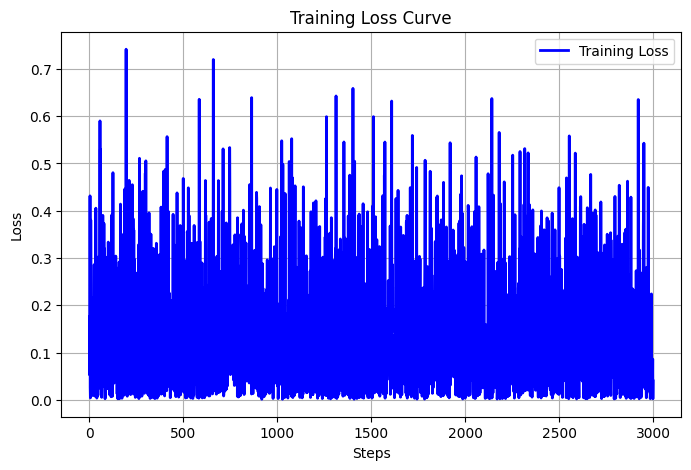

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_hist, label="Training Loss", color="blue", linewidth=2)
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid(True)

plt.savefig('loss_curver.png', dpi=600)

plt.show()

In [13]:
# import torch
# from diffusers import AutoPipelineForText2Image

# pipe = AutoPipelineForText2Image.from_pretrained('/kaggle/working/fine_tuned_models/checkpoint-45', torch_dtype=torch.float32)
# pipe = pipe.to(device)

In [14]:
# prompt='an endoscopic image of dyed resection margins shows a close - up view of a surgical site within the gastrointestinal tract, likely the stomach or duodenum. the resection margins are dyed in a specific color, which appears to be a shade of blue.'
# with torch.no_grad():
#     image = pipe(
#         prompt,
#         negative_prompt="",
#         num_inference_steps=100,
#         guidance_scale=7.0,
#     ).images[0]
# image

In [15]:
# dataloader = DataLoader(ds, batch_size=8, shuffle=True)
# pipe.unet.train()
# optimizer = torch.optim.AdamW(pipe.unet.parameters(), lr=training_args["learning_rate"])
# criterion = torch.nn.MSELoss()
# for epoch in range(training_args["num_train_epochs"]):
#     print(f"Epoch {epoch + 1}/{training_args['num_train_epochs']}")
#     for batch in tqdm(dataloader):
#         images = batch[0].to(device)
#         noise = torch.randn_like(images).to(device)

#         # Forward pass
#         outputs = pipe.unet(images, noise)
#         loss = criterion(outputs, images)

#         # Backward pass and optimization
#         optimizer.zero_grad()
#         loss.backward()
#         optimizer.step()

#         print(f"Loss: {loss.item()}")

In [16]:
# pipe.unet()